# Optimal sizing and location of a BESS for multiuse flexibility provision

In [65]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import random
import datetime
import cvxpy as cp

In [66]:
df_network = pd.read_excel('Network_rural.xlsx')

In [67]:
node_list = pd.read_excel('Nodes.xlsx')

In [68]:
df_community = pd.read_csv('scenario_s2.csv')
df_community

,Unnamed: 0,Date_Hour_start,b1,date,hour,ClusterNob1,ClusterNob2,b2,ClusterNob3,b3,...,ClusterNob7,b7,ClusterNob8,b8,ClusterNob9,b9,ClusterNob10,b10,Sum,daynu
0,0,2019-05-18 00:00:00,4.252,2019-05-18,0,0,0,7.610,1,9,...,2,9.736,1,2.406,0,1.552,0,7.5,49.787,137
1,1,2019-05-18 01:00:00,0.870,2019-05-18,1,0,0,1.718,1,10,...,2,2.153,1,3.228,0,2.117,0,9.0,36.406,137
2,2,2019-05-18 02:00:00,3.302,2019-05-18,2,0,0,0.990,1,9,...,2,2.641,1,3.888,0,2.437,0,6.0,34.821,137
3,3,2019-05-18 03:00:00,4.814,2019-05-18,3,0,0,1.090,1,9,...,2,3.497,1,3.447,0,2.353,0,9.0,38.032,137
4,4,2019-05-18 04:00:00,1.772,2019-05-18,4,0,0,0.980,1,7,...,2,1.866,1,2.391,0,1.508,0,7.5,28.005,137
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
691,691,2019-08-10 19:00:00,0.424,2019-08-10,19,0,0,0.374,1,5,...,2,0.586,1,2.583,0,4.040,0,58.5,76.689,221
692,692,2019-08-10 20:00:00,1.190,2019-08-10,20,0,0,0.548,1,5,...,2,1.143,1,2.472,0,1.941,0,42.0,60.037,221
693,693,2019-08-10 21:00:00,0.824,2019-08-10,21,0,0,0.720,1,5,...,2,1.132,1,4.047,0,2.629,0,16.5,37.769,221
694,694,2019-08-10 22:00:00,1.468,2019-08-10,22,0,0,4.716,1,7,...,2,5.450,1,3.396,0,2.375,0,9.0,43.563,221


In [69]:
price_da = pd.read_csv('day-ahead-FI-2021.csv')
price_up = pd.read_csv('up-prices.csv')
price_down = pd.read_csv('down-prices.csv')
freq1 = pd.read_csv('freq-jan-apr.csv')
freq2 = pd.read_csv('freq-may-aug.csv')
freq3 = pd.read_csv('freq-sep-dec.csv')
capacity_price = pd.read_csv('fcr-price.csv')

In [70]:
freq = [freq1, freq2, freq3]
df_freq = pd.concat(freq)

In [71]:
df_freq = df_freq.reset_index()

In [72]:
df_freq

,index,Alkuaika UTC,Lopetusaika UTC,Alkuaika UTC+03:00,Lopetusaika UTC+03:00,Taajuus - reaaliaikatieto
0,0,2020-12-31 21:01:00,2020-12-31 21:01:00,2021-01-01 00:01:00,2021-01-01 00:01:00,49.955
1,1,2020-12-31 21:04:00,2020-12-31 21:04:00,2021-01-01 00:04:00,2021-01-01 00:04:00,49.965
2,2,2020-12-31 21:07:00,2020-12-31 21:07:00,2021-01-01 00:07:00,2021-01-01 00:07:00,49.979
3,3,2020-12-31 21:10:00,2020-12-31 21:10:00,2021-01-01 00:10:00,2021-01-01 00:10:00,49.983
4,4,2020-12-31 21:13:00,2020-12-31 21:13:00,2021-01-01 00:13:00,2021-01-01 00:13:00,50.028
...,...,...,...,...,...,...
174982,58474,2021-12-31 20:46:00,2021-12-31 20:46:00,2021-12-31 23:46:00,2021-12-31 23:46:00,49.989
174983,58475,2021-12-31 20:49:00,2021-12-31 20:49:00,2021-12-31 23:49:00,2021-12-31 23:49:00,50.006
174984,58476,2021-12-31 20:52:00,2021-12-31 20:52:00,2021-12-31 23:52:00,2021-12-31 23:52:00,49.977
174985,58477,2021-12-31 20:55:00,2021-12-31 20:55:00,2021-12-31 23:55:00,2021-12-31 23:55:00,49.975


In [73]:
data = {'time': df_freq['Alkuaika UTC+03:00'],
        'frequency': df_freq['Taajuus - reaaliaikatieto']}

In [74]:
df = pd.DataFrame(data)

In [75]:
df['FC'] = 50 - df['frequency']

In [76]:
df.loc[df[df['FC']<-0.1].index,'FC'] = -0.1
df.loc[df[df['FC']>0.1].index,'FC'] = 0.1

In [77]:
df['time'] = pd.to_datetime(df['time'])

In [78]:
df['hour'] = df.time.dt.hour
df['daynu'] = df.time.dt.dayofyear - 1

In [79]:
df

,time,frequency,FC,hour,daynu
0,2021-01-01 00:01:00,49.955,0.045,0,0
1,2021-01-01 00:04:00,49.965,0.035,0,0
2,2021-01-01 00:07:00,49.979,0.021,0,0
3,2021-01-01 00:10:00,49.983,0.017,0,0
4,2021-01-01 00:13:00,50.028,-0.028,0,0
...,...,...,...,...,...
174982,2021-12-31 23:46:00,49.989,0.011,23,364
174983,2021-12-31 23:49:00,50.006,-0.006,23,364
174984,2021-12-31 23:52:00,49.977,0.023,23,364
174985,2021-12-31 23:55:00,49.975,0.025,23,364


In [80]:
data1 = {'time': price_up['Alkuaika UTC+03:00'],
        'price_up': price_up['Ylössäätöhinta säätösähkömarkkinoilla'],
        'price_down': price_down['Down-regulation price in the Balancing energy market'],
        'price_da': price_da['Day-ahead Price [EUR/MWh]'],
        'price_fcr_cap' :  capacity_price['Taajuusohjattu käyttöreservi, tuntimarkkinahinnat']}

In [81]:
price = pd.DataFrame(data1)

In [82]:
price['time'] = pd.to_datetime(price['time'])

In [83]:
price['hour'] = price.time.dt.hour
price['daynu'] = price.time.dt.dayofyear - 1

In [84]:
price['price_da'] = price['price_da'].shift(-1)

In [85]:
day_number = df_community.drop_duplicates(subset='daynu', keep='first')['daynu']
day_number

0      137
24     138
48     158
72     159
96     160
120    165
144    166
168    169
192    170
216    176
240    181
264    183
288    184
312    188
336    190
360    195
384    196
408    197
432    202
456    203
480    204
504    207
528    208
552    210
576    211
600    216
624    217
648    218
672    221
Name: daynu, dtype: int64

In [86]:
selected_day = [137, 176, 197, 221]

In [87]:
load_df = df_community[df_community['daynu'].isin(selected_day)]
load_df = load_df.reset_index(drop=True)

In [88]:
df['time'] =  pd.to_datetime(df['time'])
df.set_index(df['time'],inplace = True)

In [89]:
df.drop(columns=['time','frequency','hour','daynu'], inplace=True)

In [90]:
up_df = df[df.FC > 0].resample('1H').mean()

In [91]:
down_df = df[df.FC <= 0].resample('1H').mean()

In [92]:
up_df.fillna(0, inplace=True)
down_df.fillna(0, inplace=True)

In [93]:
down_df['FC'] = -down_df['FC']

In [94]:
fc = pd.DataFrame()
fc['up'] = up_df['FC']
fc['down'] = down_df['FC']
fc.index = up_df.index

In [95]:
fc.index= pd.to_datetime(fc.index)
fc['hour'] = fc.index.hour
fc['daynu'] = fc.index.dayofyear - 1

In [96]:
fc.reset_index(inplace=True)

In [97]:
load_df.columns.values

array(['Unnamed: 0', 'Date_Hour_start', 'b1', 'date', 'hour',
       'ClusterNob1', 'ClusterNob2', 'b2', 'ClusterNob3', 'b3',
       'ClusterNob4', 'b4', 'ClusterNob5', 'b5', 'ClusterNob6', 'b6',
       'ClusterNob7', 'b7', 'ClusterNob8', 'b8', 'ClusterNob9', 'b9',
       'ClusterNob10', 'b10', 'Sum', 'daynu'], dtype=object)

In [98]:
final_df = load_df[['b1','b2','b3','b4','b5','b6','b7','b8','b9','b10','hour','daynu']]

In [99]:
l = fc[fc.daynu.isin(final_df.daynu)].reset_index(drop=True)[['up','down']]

In [100]:
final_df = pd.concat([final_df, l], axis=1)

In [101]:
ll = price[price.daynu.isin(final_df.daynu)].reset_index(drop=True)[['price_up','price_down','price_da','price_fcr_cap']]

In [102]:
final_df = pd.concat([final_df, ll], axis=1)

In [103]:
final_df[['price_up','price_down','price_da','price_fcr_cap']] = 0.1 * final_df[['price_up','price_down','price_da','price_fcr_cap']] 

In [104]:
def node_index(node):
    return(node_list[node_list['node']==node].index[0])

In [105]:
def node_name(n):
    return(node_list['node'][n])

In [106]:
bes_location = node_name(6)
bes_location

'b6'

In [107]:
import scipy.io
data2 = scipy.io.loadmat('data_hosna.mat')
data3 = scipy.io.loadmat('PulseP.mat')

In [108]:
cell_energy = data2['Energy']
cell_cycle = data2['cycles']
cell_power = data3['PulseP']/3

In [109]:
cell_cycle


array([[   0,  500,  800, 1200, 1600]], dtype=uint16)

In [110]:
np.reshape(cell_energy,(5,))

array([101.18529194,  94.77996709,  91.48483298,  87.26185817,
        80.34173122])

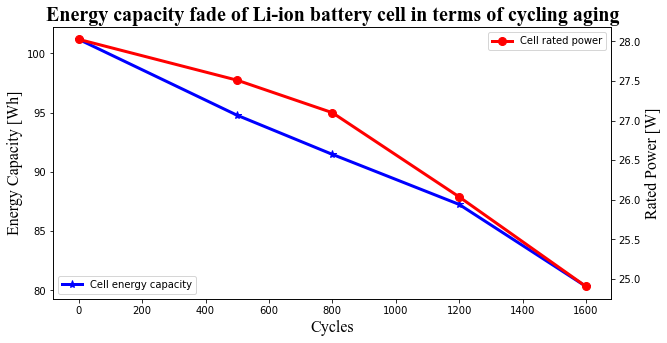

In [111]:
x_axis = np.reshape(cell_cycle,(5,))
fig, ax1 = plt.subplots(figsize=(10, 5))
ax2 = ax1.twinx()
ax1.set_facecolor("white")
ax1.plot(x_axis, np.reshape(cell_energy,(5,)), color='blue', marker='*', markersize=8, linestyle='-', linewidth=3, label='Cell energy capacity')
ax2.plot(x_axis, np.reshape(cell_power[:,5], (5,)), color='red',  marker='o', markersize=8, linestyle='-', linewidth=3, label='Cell rated power')
ax1.set_title('Energy capacity fade of Li-ion battery cell in terms of cycling aging', fontname='Times New Roman', fontsize=20, fontweight="bold")
ax1.set_xlabel('Cycles',fontsize=16, fontname='Times New Roman')
ax1.set_ylabel('Energy Capacity [Wh]',fontsize=16, fontname='Times New Roman')
ax2.set_ylabel('Rated Power [W]',fontsize=16, fontname='Times New Roman')
ax1.legend(loc='lower left')
ax2.legend(loc='upper right')
plt.savefig('capacityfadecycle.png', dpi=300)
plt.show()

In [112]:
rated_cell_power = (cell_power[0,5])/(1000 * 50)
rated_cell_energy = (cell_energy[0][0])/(1000 * 50)

In [113]:
rated_cell_energy/rated_cell_power

3.610539829093147

In [114]:
cell_power

array([[31.31594534, 30.36705249, 29.62668763, 28.96156856, 28.34750914,
        28.02497597, 27.87581403, 27.33963731, 26.42182103, 25.08775385,
        18.139611  ],
       [30.91639419, 29.96798105, 29.17784245, 28.52218687, 27.87453557,
        27.509056  , 27.34647134, 26.39918055, 25.30677286, 24.00878292,
        18.79935537],
       [30.43961094, 29.52591201, 28.7882345 , 28.13923953, 27.53996053,
        27.09923516, 26.88021616, 25.80661992, 24.61881132, 23.29932258,
        18.93147262],
       [29.36996988, 28.48455601, 27.74151176, 27.14357644, 26.46616647,
        26.03638833, 25.81199462, 24.80791567, 23.35978795, 22.1101703 ,
        18.45268725],
       [28.06595593, 27.2400703 , 26.54447667, 25.88776269, 25.31536794,
        24.9051317 , 24.67809378, 23.94191442, 22.1716917 , 21.00769868,
        18.27294691]])

In [115]:
rated_cell_energy*50

0.10118529194431637

In [116]:
hourly_max_cycle = rated_cell_power / (2 * rated_cell_energy)
hourly_max_cycle

0.13848344670541526

In [117]:
final_df['first_hour'] = 0
final_df.loc[final_df[final_df.hour == 0].index,'first_hour'] = 1

In [118]:
#bes_energy = (800/50)*(cell_energy[0,4]/cell_energy[0,0])
#bes_power = (221.57351472885196/50)*(cell_power[4,5]/cell_power[0,5])
daily_capital_cost = 100 * (150 + 0.01*150)/(8*365) #150 e/kwh + 10% installment cost + need to pay it over two years
daily_mo_cost = 0.001
cycling_cost = 10000 / (6000-cell_cycle[0,0]) #(euro / kwh cycle)

In [119]:
# parameters
node_number = len(node_list)
T = len(final_df)
partitions = 10
v_min = 0.95
v_max = 1.05
v_nom = 1
q_factor = np.tan(np.arccos(0.9))
delta_s = v_nom * df_network['IMAX'] / partitions
R = range(1,partitions+1)
const = []   
t = 0
soc_min = 0.05
soc_max = 0.95
eff = 0.9
node_number = len(node_list)
T = len(final_df)
partitions = 10
v_min = 0.95
v_max = 1.05
v_nom = 1
q_factor = np.tan(np.arccos(0.9))
delta_s = v_nom * df_network['IMAX'] / partitions
R = range(1,partitions+1)
const = []
obj = 0   
t = 0
soc_min = 0.05
soc_max = 0.95
eff = 0.9
bes_power_min = 0.47125480772458106          # obtained from stage 1 pu
soc_ini = 0.5
bes_max_energy = 16 #pu #transformer capacity

# energy_cycling = 2 * bes_energy * cycle(t)
# cell_cycling_cost * energy_cycling / 2

In [120]:
daily_capital_cost

5.188356164383562

In [121]:
cycling_cost

1.6666666666666667

In [122]:
final_df.price_up

0      3.751
1      2.309
2      2.245
3      2.231
4      2.262
       ...  
91    10.616
92    11.700
93     8.503
94     7.201
95     7.018
Name: price_up, Length: 96, dtype: float64

In [123]:
obj_value = {}
opt_flex_up = {}
opt_flex_down = {}
opt_bes_energy = {}
opt_bes_power = {}
opt_power_ch_spot = {}
opt_power_dis_spot = {}
opt_power_fcr_up = {}
opt_power_fcr_down = {}
opt_cap_fcr = {}
opt_power_act_poc = {}
opt_power_react_poc = {}
total_power = {}

In [124]:
def load(n):
    return(np.array(final_df.get(node_list['node'][n], default=np.zeros(final_df.shape[0]))))

# Variables:

# power trading and bes-related variables
power_act_poc = cp.Variable(shape = (node_number,T))                        # active power of poc
power_react_poc = cp.Variable(shape = (node_number,T))                      # reactive power of poc
#flex_up = cp.Variable(shape = (node_number,T), nonneg = True)               # loacl network upward flexibility
#flex_down= cp.Variable(shape = (node_number,T), nonneg = True)              # local network downward flexibility
power_ch_spot = cp.Variable(shape = (node_number,T), nonneg = True)         # power traded in spot for charging bes
power_dis_spot = cp.Variable(shape = (node_number,T), nonneg = True)        # power traded in spot for discharging bes
cap_fcr = cp.Variable(shape = (T,), nonneg = True)                          # FCR capacity
power_fcr_up = cp.Variable(shape = (node_number,T), nonneg = True)          # FCR upward activation
power_fcr_down = cp.Variable(shape = (node_number,T), nonneg = True)        # FCR downward activation
bes_power = cp.Variable(nonneg = True)                                      # BES rated power
bes_energy = cp.Variable(nonneg = True)                                     # BES capacity
bes_soe = cp.Variable(shape = (T,), nonneg = True)                          # BES state of energy (SOE)
energy_cycle = cp.Variable(shape = (T,), nonneg = True)                     # BES cycle

# network related parameters
flow_act_pos = cp.Variable(shape = (len(df_network),T), nonneg = True)      # positive active power flow
flow_act_neg = cp.Variable(shape = (len(df_network),T), nonneg = True)      # negative active power flow
flow_react_pos = cp.Variable(shape = (len(df_network),T), nonneg = True)    # positive reactive power flow
flow_react_neg = cp.Variable(shape = (len(df_network),T), nonneg = True)    # negative reactive power flow
voltage_square = cp.Variable(shape = (node_number,T), nonneg = True)        # voltage square
current_square = cp.Variable(shape = (len(df_network),T), nonneg = True)    # current square
power_act_delta = np.zeros((partitions+1), dtype=type(cp.Variable()))
for i in R:
    power_act_delta[i] = cp.Variable(shape=(len(df_network),T), nonneg = True)
power_react_delta = np.zeros((partitions+1), dtype=type(cp.Variable()))
for i in R:
    power_react_delta[i] = cp.Variable(shape=(len(df_network),T), nonneg = True)
par1 = np.zeros((partitions+1), dtype=type(cp.Variable()))
for i in R:
    par1[i] = cp.Variable(shape=(len(df_network),T), nonneg = True)
par2 = np.zeros((partitions+1), dtype=type(cp.Variable()))
for i in R:
    par2[i] = cp.Variable(shape=(len(df_network),T), nonneg = True)

# constraints
for t in range(T):
    for n in range(node_number):

        # balance constraints for active power
        const += [power_act_poc[n,t] - (load(n)[t] ) / 50 + power_dis_spot[n,t]
        #+ flex_up[n,t] 
        + power_fcr_up[n,t] 
        -  power_ch_spot[n,t] 
        #- flex_down[n,t]
        - power_fcr_down[n,t]
        - (np.array([df_network.fr == node_name(n)]).astype(int) @ flow_act_pos)[0,t]
        + (np.array([df_network.fr == node_name(n)]).astype(int) @ flow_act_neg)[0,t]
        - ((np.array([df_network.fr == node_name(n)]).astype(int) 
        * np.array(df_network.RL)) @ current_square)[0,t]
        + (np.array([df_network.to == node_name(n)]).astype(int) @ flow_act_pos)[0,t]
        - (np.array([df_network.to == node_name(n)]).astype(int) @ flow_act_neg)[0,t] == 0]
        
        # balance constraints for reactive power
        const += [power_react_poc[n,t] - q_factor * (load(n)[t]) / 50
        - (np.array([df_network.fr == node_name(n)]).astype(int) @ flow_react_pos)[0,t]
        + (np.array([df_network.fr == node_name(n)]).astype(int) @ flow_react_neg)[0,t]
        - ((np.array([df_network.fr == node_name(n)]).astype(int) 
        * np.array(df_network.XL)) @ current_square)[0,t]
        + (np.array([df_network.to == node_name(n)]).astype(int) @ flow_react_pos)[0,t]
        - (np.array([df_network.to == node_name(n)]).astype(int) @ flow_react_neg)[0,t] == 0]
        
        # Voltage constraints
        const += [voltage_square[n,t] <= np.square(v_max)]
        const += [np.square(v_min) <= voltage_square[n,t]]
        const += [voltage_square[1,t] == np.square(v_nom)]

        # Constraints related to the poc node
        if n != 0:
            const += [power_act_poc[n,t] == 0]
            const += [power_react_poc[n,t] == 0]

        # Constraints related to the bes location node
        if n != node_index(bes_location):
            const += [power_fcr_up[n,t] == 0]
            const += [power_fcr_down[n,t] == 0]
            const += [power_ch_spot[n,t] == 0]
            const += [power_dis_spot[n,t] == 0]
            #const += [flex_down[n,t] == 0]
            #const += [flex_up[n,t] == 0]

    # Network constraints:
    for net in range(len(df_network)):
         
        # voltage and power relationship:
        const += [voltage_square[node_index(df_network.loc[net,'fr']),t] -
        voltage_square[node_index(df_network.loc[net,'to']),t] -
        (np.square(df_network.RL[net]) + np.square(df_network.XL[net])) * current_square[net,t] -
        2 * df_network.RL[net] * (flow_act_pos[net,t] - flow_act_neg[net,t]) -
        2 * df_network.XL[net] * (flow_react_pos[net,t] - flow_react_neg[net,t]) == 0]

        # active and reactive power flow constraints
        const += [flow_act_pos[net,t] + flow_act_neg[net,t] <= v_nom * df_network.IMAX[net]]
        const += [flow_react_pos[net,t] + flow_react_neg[net,t] <= v_nom * df_network.IMAX[net]]

        # voltage constraint
        const += [current_square[net,t] <= np.square(df_network.IMAX[net])]

        # piece-wise linearization-related constraints
            
        const += [np.square(v_nom) * current_square[net,t] == 
        sum(par1[:])[net,t] + sum(par2[:])[net,t]]

        const += [flow_act_pos[net,t] + flow_act_neg[net,t] ==
        sum(power_act_delta[:])[net,t]]

        const += [flow_react_pos[net,t] + flow_react_neg[net,t] ==
        sum(power_react_delta[:])[net,t]]

        for r in R:
            const += [par1[r][net,t] == (2*r-1) * delta_s[net] * power_act_delta[r][net,t]]
            const += [par2[r][net,t] == (2*r-1) * delta_s[net] * power_react_delta[r][net,t]]
            const += [power_act_delta[r][net,t] <= delta_s[net]]
            const += [power_react_delta[r][net,t] <= delta_s[net]]
    
    # bes-related, spot trading and fcr trading- related constraints
    const += [cap_fcr[t] + power_ch_spot[node_index(bes_location),t] <= bes_power]
    const += [cap_fcr[t] + power_dis_spot[node_index(bes_location),t] <= bes_power]
    const += [power_fcr_up[node_index(bes_location),t] == (final_df.loc[t,'up']/0.1) * cap_fcr[t]]
    const += [power_fcr_down[node_index(bes_location),t] == (final_df.loc[t,'down']/0.1) * cap_fcr[t]]
    const += [bes_soe[t] == final_df.loc[t,'first_hour'] * soc_ini * bes_energy
    + (1-final_df.loc[t,'first_hour']) * bes_soe[t-1] + eff * (power_ch_spot[node_index(bes_location),t]
    + power_fcr_down[node_index(bes_location),t])
    - (1/eff) * (power_dis_spot[node_index(bes_location),t] 
    + power_fcr_up[node_index(bes_location),t])] #consider soe at the end of each time slot
    const += [bes_soe[t] <= soc_max * bes_energy]
    const += [soc_min * bes_energy <= bes_soe[t]]

    ##********************For day-ahead market use
    const +=[cap_fcr[t] == 0]
    if t != 0:
        const += [cap_fcr[t] <= 2 * bes_soe[t-1] * (soc_max - soc_min)]
        const += [cap_fcr[t] <= 2 * (bes_energy - bes_soe[t-1]) * (soc_max - soc_min)]
    
    # Constraints related to the cycles and linearization using Mccormick envelopes:

    const += [energy_cycle[t] == power_ch_spot[node_index(bes_location),t] 
    + power_fcr_down[node_index(bes_location),t] + power_dis_spot[node_index(bes_location),t] 
    + power_fcr_up[node_index(bes_location),t]]

const += [bes_energy <= bes_max_energy]
const += [bes_energy >= (bes_power_min / rated_cell_power) * rated_cell_energy]
const += [bes_power == (bes_energy ) * (rated_cell_power/ rated_cell_energy)]
const += [bes_power >= bes_power_min]


obj = daily_capital_cost * 50 * bes_energy + 0.25 * (daily_mo_cost * 50 * cp.sum(energy_cycle) 
+ cycling_cost * 0.5 * 50 * cp.sum(energy_cycle) 
- 50 * cp.sum(cp.multiply(np.array(final_df['price_fcr_cap']) , cap_fcr))
- 50 * cp.sum(cp.multiply(np.array(final_df['price_up']) , power_fcr_up[node_index(bes_location),:]))
+ 50 * cp.sum(cp.multiply(np.array(final_df['price_down']) , power_fcr_down[node_index(bes_location),:]))
+ 50 * cp.sum(cp.multiply(np.array(final_df['price_da']) , (power_ch_spot[node_index(bes_location),:]
- power_dis_spot[node_index(bes_location),:]))))

problem = cp.Problem(cp.Minimize(obj), const)

obj_value = problem.solve(verbose=True)
#opt_flex_up = 50 * flex_up.value
#opt_flex_down = 50 * flex_down.value
opt_bes_energy = 50 * bes_energy.value
opt_bes_power = 50 * bes_power.value
opt_power_ch_spot = 50 * power_ch_spot.value
opt_power_dis_spot = 50 * power_dis_spot.value
opt_power_fcr_up = 50 * power_fcr_up.value
opt_power_fcr_down = 50 * power_fcr_down.value
opt_cap_fcr = 50 * cap_fcr.value
opt_power_act_poc = 50 * power_act_poc.value
opt_power_react_poc = 50 * power_react_poc.value
total_power = 50 * energy_cycle.value


                                     CVXPY                                     
                                     v1.2.1                                    
(CVXPY) Apr 13 01:48:04 PM: Your problem has 50882 variables, 57218 constraints, and 0 parameters.
(CVXPY) Apr 13 01:48:11 PM: It is compliant with the following grammars: DCP, DQCP
(CVXPY) Apr 13 01:48:11 PM: (If you need to solve this problem multiple times, but with different data, consider using parameters.)
(CVXPY) Apr 13 01:48:11 PM: CVXPY will first compile your problem; then, it will invoke a numerical solver to obtain a solution.
-------------------------------------------------------------------------------
                                  Compilation                                  
-------------------------------------------------------------------------------
(CVXPY) Apr 13 01:48:21 PM: Compiling problem (target solver=ECOS).
(CVXPY) Apr 13 01:48:21 PM: Reduction chain: Dcp2Cone -> CvxAttr2Constr -> ConeMatrixStuf

In [126]:
m_opt_bes_energy = 50 * bes_energy.value
m_opt_bes_power = 50 * bes_power.value
m_opt_power_ch_spot = 50 * np.matrix(power_ch_spot.value)
m_opt_power_dis_spot = 50 * np.matrix(power_dis_spot.value)
m_opt_power_fcr_up = 50 * np.matrix(power_fcr_up.value)
m_opt_power_fcr_down = 50 * np.matrix(power_fcr_down.value)
m_opt_cap_fcr = 50 * np.matrix(cap_fcr.value)
m_opt_power_act_poc = 50 * np.matrix(power_act_poc.value)
m_opt_power_react_poc = 50 * np.matrix(power_react_poc.value)
m_total_power = 50 * np.matrix(energy_cycle.value)
one = obj_value

In [129]:
m_opt_bes_power

29.74599457974525

In [61]:
"""
n_opt_bes_energy = 50 * bes_energy.value
n_opt_bes_power = 50 * bes_power.value
n_opt_power_ch_spot = 50 * np.matrix(power_ch_spot.value)
n_opt_power_dis_spot = 50 * np.matrix(power_dis_spot.value)
n_opt_power_fcr_up = 50 * np.matrix(power_fcr_up.value)
n_opt_power_fcr_down = 50 * np.matrix(power_fcr_down.value)
n_opt_cap_fcr = 50 * np.matrix(cap_fcr.value)
n_opt_power_act_poc = 50 * np.matrix(power_act_poc.value)
n_opt_power_react_poc = 50 * np.matrix(power_react_poc.value)
n_total_power = 50 * np.matrix(energy_cycle.value)
one1 = obj_value

In [63]:
one1 

-5580.660553306725

In [130]:
np.savetxt("m_opt_power_ch_spot21.csv", m_opt_power_ch_spot, delimiter=",")
np.savetxt("m_opt_power_dis_spot21.csv", m_opt_power_dis_spot, delimiter=",")
np.savetxt("m_total_power21.csv", m_total_power, delimiter=",")

In [64]:

np.savetxt("n_opt_power_ch_spot21.csv", n_opt_power_ch_spot, delimiter=",")
np.savetxt("n_opt_power_dis_spot21.csv", n_opt_power_dis_spot, delimiter=",")
np.savetxt("n_opt_power_fcr_up21.csv", n_opt_power_fcr_up, delimiter=",")
np.savetxt("n_opt_power_fcr_down21.csv", n_opt_power_fcr_down, delimiter=",")
np.savetxt("n_opt_cap_fcr21.csv", n_opt_cap_fcr, delimiter=",")
np.savetxt("n_total_power21.csv", n_total_power, delimiter=",")